In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path
from collections import Counter

# Thiết lập style cho biểu đồ
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Tạo thư mục outputs nếu chưa có
Path('../outputs').mkdir(exist_ok=True)
Path('../data/processed').mkdir(parents=True, exist_ok=True)

print("✅ Đã import thư viện thành công!")

✅ Đã import thư viện thành công!


In [9]:
print("=" * 60)
print("BƯỚC 1: TẢI VÀ LỌC JOB POSTINGS (LINKEDIN)")
print("=" * 60)

# 1. Đọc file postings.csv
df_jobs = pd.read_csv('../data/raw/postings.csv')
print(f"📊 Tổng số job ban đầu: {len(df_jobs):,}")

# 2. Lọc chỉ lấy job liên quan đến IT/Tech (khớp với dataset Resume)
tech_keywords = 'software|data|engineer|developer|it |machine learning|ai|python|analyst'
df_jobs_tech = df_jobs[df_jobs['title'].str.contains(tech_keywords, case=False, na=False)].copy()
print(f"🎯 Số job IT/Tech sau khi lọc: {len(df_jobs_tech):,}")

# 3. Chọn các cột cần thiết và đổi tên cho dễ dùng
df_jobs_final = df_jobs_tech[['job_id', 'title', 'description', 'skills_desc', 'location']].copy()
df_jobs_final.columns = ['job_id', 'job_title', 'job_description', 'job_skills', 'location']

# 4. Xử lý missing values (điền chuỗi rỗng nếu thiếu)
df_jobs_final = df_jobs_final.fillna('')

# 5. Xem thử 3 job đầu tiên
print("\n📋 3 MẪU JOB ĐẦU TIÊN:")
display(df_jobs_final[['job_title', 'location', 'job_skills']].head(3))

BƯỚC 1: TẢI VÀ LỌC JOB POSTINGS (LINKEDIN)
📊 Tổng số job ban đầu: 123,849
🎯 Số job IT/Tech sau khi lọc: 29,101

📋 3 MẪU JOB ĐẦU TIÊN:


,job_title,location,job_skills
7,Building Engineer,"San Francisco, CA",
13,Structural Engineer,"San Mateo, CA",Job Overview: Manage a project from start to f...
22,Software Engineer,Los Angeles Metropolitan Area,


In [10]:
print("=" * 60)
print("BƯỚC 2: TẢI RESUME DATASET")
print("=" * 60)

# 1. Đọc file resumes_final.csv (đã làm sạch ở bước trước)
df_resumes = pd.read_csv('../data/raw/resumes_final.csv')
print(f" Tổng số CV: {len(df_resumes):,}")

# 2. Xem các Category có sẵn
print("\n🏷️ CÁC NGÀNH NGHỀ (CATEGORY) CÓ TRONG DATASET:")
print(df_resumes['category'].value_counts())

# 3. Xem thử 2 CV đầu tiên
print("\n📋 2 MẪU CV ĐẦU TIÊN:")
display(df_resumes[['category', 'resume_text']].head(2))

BƯỚC 2: TẢI RESUME DATASET
 Tổng số CV: 2,483

🏷️ CÁC NGÀNH NGHỀ (CATEGORY) CÓ TRONG DATASET:
category
Information Technology    120
Business Development      119
Advocate                  118
Chef                      118
Finance                   118
Engineering               118
Accountant                118
Fitness                   117
Aviation                  117
Sales                     116
Healthcare                115
Consultant                115
Banking                   115
Construction              112
Public Relations          111
Hr                        110
Designer                  107
Arts                      103
Teacher                   102
Apparel                    97
Digital Media              96
Agriculture                63
Automobile                 36
Bpo                        22
Name: count, dtype: int64

📋 2 MẪU CV ĐẦU TIÊN:


,category,resume_text
0,Hr,HR ADMINISTRATOR/MARKETING ASSOCIATE HR ADMINI...
1,Hr,"HR SPECIALIST, US HR OPERATIONS Summary Versat..."


In [11]:
print("=" * 60)
print("BƯỚC 3: TIỀN XỬ LÝ VĂN BẢN (TEXT CLEANING)")
print("=" * 60)

def clean_text(text):
    """Làm sạch văn bản: chuyển lowercase, loại ký tự đặc biệt"""
    if not isinstance(text, str):
        return ""
    
    # 1. Chuyển về chữ thường
    text = text.lower()
    
    # 2. Loại bỏ ký tự đặc biệt, giữ lại chữ, số, khoảng trắng, dấu + và #
    # (Giữ + và # vì trong IT có C++, C#, #include)
    text = re.sub(r'[^a-z0-9\s\+\#]', ' ', text)
    
    # 3. Thay nhiều khoảng trắng bằng 1 khoảng trắng
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# Áp dụng cho Job
print(" Đang làm sạch Job Descriptions...")
df_jobs_final['clean_job_desc'] = df_jobs_final['job_description'].apply(clean_text)
df_jobs_final['clean_job_skills'] = df_jobs_final['job_skills'].apply(clean_text)

# Áp dụng cho Resume
print("🧹 Đang làm sạch Resumes...")
df_resumes['clean_resume_text'] = df_resumes['resume_text'].apply(clean_text)

print("✅ Hoàn tất làm sạch văn bản!")

# Kiểm tra kết quả
print("\n--- JD sau khi làm sạch (300 ký tự đầu) ---")
print(df_jobs_final['clean_job_desc'].iloc[0][:300] + "...")

BƯỚC 3: TIỀN XỬ LÝ VĂN BẢN (TEXT CLEANING)
 Đang làm sạch Job Descriptions...
🧹 Đang làm sạch Resumes...
✅ Hoàn tất làm sạch văn bản!

--- JD sau khi làm sạch (300 ký tự đầu) ---
summary due to the pending retirement of our building engineer we are seeking a building engineer be the be is a salaried overtime exempt professional with direct responsibility for the physical plant of our historic clubhouse this hands on position involves light maintenance tasks operation of buil...


BƯỚC 4: PHÂN TÍCH ĐỘ DÀI VĂN BẢN

📊 JOB DESCRIPTIONS:
   - Trung bình: 547 từ
   - Median: 501 từ
   - Min: 1, Max: 3485

📊 RESUMES/CV:
   - Trung bình: 817 từ
   - Median: 761 từ
   - Min: 108, Max: 5175

💡 JD dài gấp 0.7 lần CV
   => Cần chiến lược xử lý bất đối xứng khi embedding!


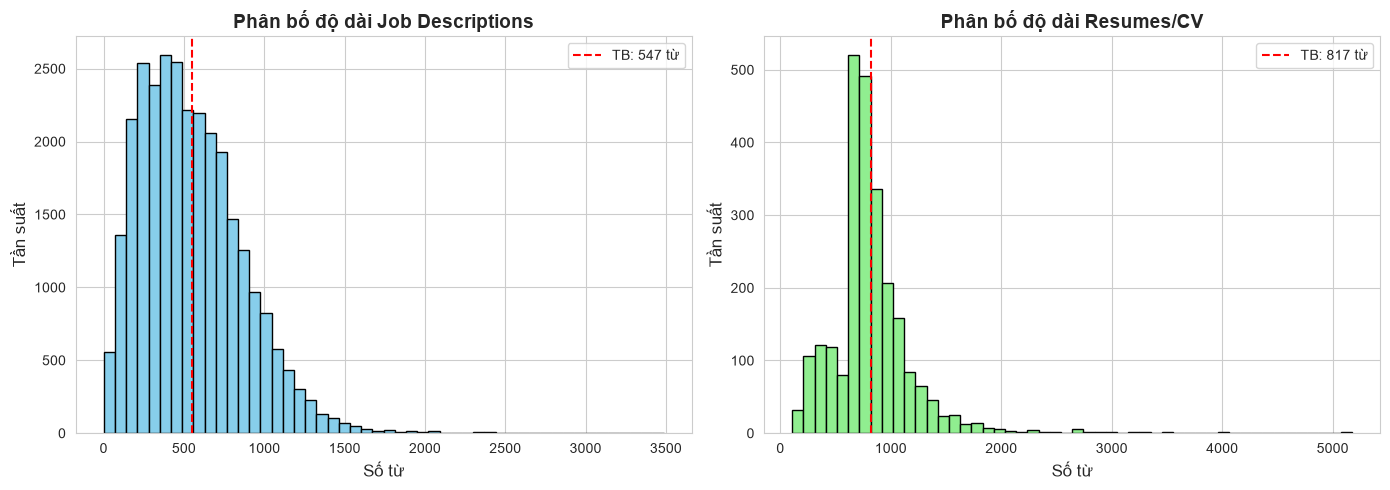


✅ Đã lưu biểu đồ tại: outputs/eda_word_count_distribution.png


In [12]:
print("=" * 60)
print("BƯỚC 4: PHÂN TÍCH ĐỘ DÀI VĂN BẢN")
print("=" * 60)

# Hàm đếm số từ
def count_words(text):
    if pd.isna(text) or text == '':
        return 0
    return len(str(text).split())

# Đếm từ cho JD và CV
df_jobs_final['word_count'] = df_jobs_final['clean_job_desc'].apply(count_words)
df_resumes['word_count'] = df_resumes['clean_resume_text'].apply(count_words)

# In thống kê
print(f"\n📊 JOB DESCRIPTIONS:")
print(f"   - Trung bình: {df_jobs_final['word_count'].mean():.0f} từ")
print(f"   - Median: {df_jobs_final['word_count'].median():.0f} từ")
print(f"   - Min: {df_jobs_final['word_count'].min()}, Max: {df_jobs_final['word_count'].max()}")

print(f"\n📊 RESUMES/CV:")
print(f"   - Trung bình: {df_resumes['word_count'].mean():.0f} từ")
print(f"   - Median: {df_resumes['word_count'].median():.0f} từ")
print(f"   - Min: {df_resumes['word_count'].min()}, Max: {df_resumes['word_count'].max()}")

ratio = df_jobs_final['word_count'].mean() / df_resumes['word_count'].mean()
print(f"\n💡 JD dài gấp {ratio:.1f} lần CV")
print("   => Cần chiến lược xử lý bất đối xứng khi embedding!")

# Vẽ biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_jobs_final['word_count'], bins=50, color='skyblue', edgecolor='black')
axes[0].set_xlabel('Số từ', fontsize=12)
axes[0].set_ylabel('Tần suất', fontsize=12)
axes[0].set_title('Phân bố độ dài Job Descriptions', fontsize=14, fontweight='bold')
axes[0].axvline(df_jobs_final['word_count'].mean(), color='red', linestyle='--', 
                label=f'TB: {df_jobs_final["word_count"].mean():.0f} từ')
axes[0].legend()

axes[1].hist(df_resumes['word_count'], bins=50, color='lightgreen', edgecolor='black')
axes[1].set_xlabel('Số từ', fontsize=12)
axes[1].set_ylabel('Tần suất', fontsize=12)
axes[1].set_title('Phân bố độ dài Resumes/CV', fontsize=14, fontweight='bold')
axes[1].axvline(df_resumes['word_count'].mean(), color='red', linestyle='--', 
                label=f'TB: {df_resumes["word_count"].mean():.0f} từ')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/eda_word_count_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Đã lưu biểu đồ tại: outputs/eda_word_count_distribution.png")

BƯỚC 5: PHÂN BỐ NGÀNH NGHỀ TRONG RESUME

📊 Số lượng CV theo ngành nghề (Top 10):
category
Information Technology    120
Business Development      119
Advocate                  118
Chef                      118
Finance                   118
Engineering               118
Accountant                118
Fitness                   117
Aviation                  117
Sales                     116
Name: count, dtype: int64


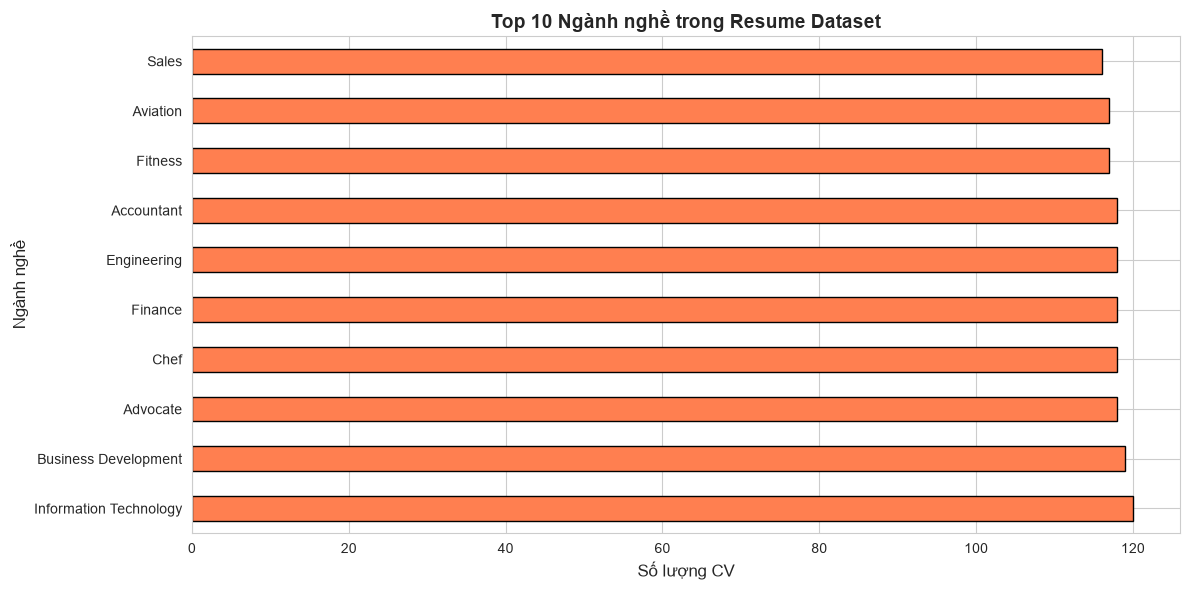


✅ Đã lưu biểu đồ tại: outputs/eda_resume_categories.png

 Nhận xét: Ngành 'Information Technology' và 'Data Science' có nhiều CV nhất
   => Phù hợp để khớp với Job Postings IT/Tech!


In [13]:
print("=" * 60)
print("BƯỚC 5: PHÂN BỐ NGÀNH NGHỀ TRONG RESUME")
print("=" * 60)

# Đếm số CV theo từng category
category_counts = df_resumes['category'].value_counts()

print(f"\n📊 Số lượng CV theo ngành nghề (Top 10):")
print(category_counts.head(10))

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
category_counts.head(10).plot(kind='barh', color='coral', edgecolor='black')
plt.xlabel('Số lượng CV', fontsize=12)
plt.ylabel('Ngành nghề', fontsize=12)
plt.title('Top 10 Ngành nghề trong Resume Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/eda_resume_categories.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Đã lưu biểu đồ tại: outputs/eda_resume_categories.png")
print("\n Nhận xét: Ngành 'Information Technology' và 'Data Science' có nhiều CV nhất")
print("   => Phù hợp để khớp với Job Postings IT/Tech!")

BƯỚC 6: TOP KỸ NĂNG PHỔ BIẾN TRONG JD

 TOP 20 KỸ NĂNG PHỔ BIẾN NHẤT:
 1. data                 - 2050 lần xuất hiện
 2. all                  - 1761 lần xuất hiện
 3. other                - 1555 lần xuất hiện
 4. including            - 1507 lần xuất hiện
 5. business             - 1459 lần xuất hiện
 6. management           - 1424 lần xuất hiện
 7. support              - 1324 lần xuất hiện
 8. years                - 1309 lần xuất hiện
 9. engineering          - 1302 lần xuất hiện
10. development          - 1273 lần xuất hiện
11. time                 - 1240 lần xuất hiện
12. company              - 1218 lần xuất hiện
13. technical            - 1160 lần xuất hiện
14. have                 - 1112 lần xuất hiện
15. information          - 1103 lần xuất hiện
16. design               - 1070 lần xuất hiện
17. systems              - 1062 lần xuất hiện
18. knowledge            - 1055 lần xuất hiện
19. benefits             - 1042 lần xuất hiện
20. requirements         - 1034 lần xuất hiện


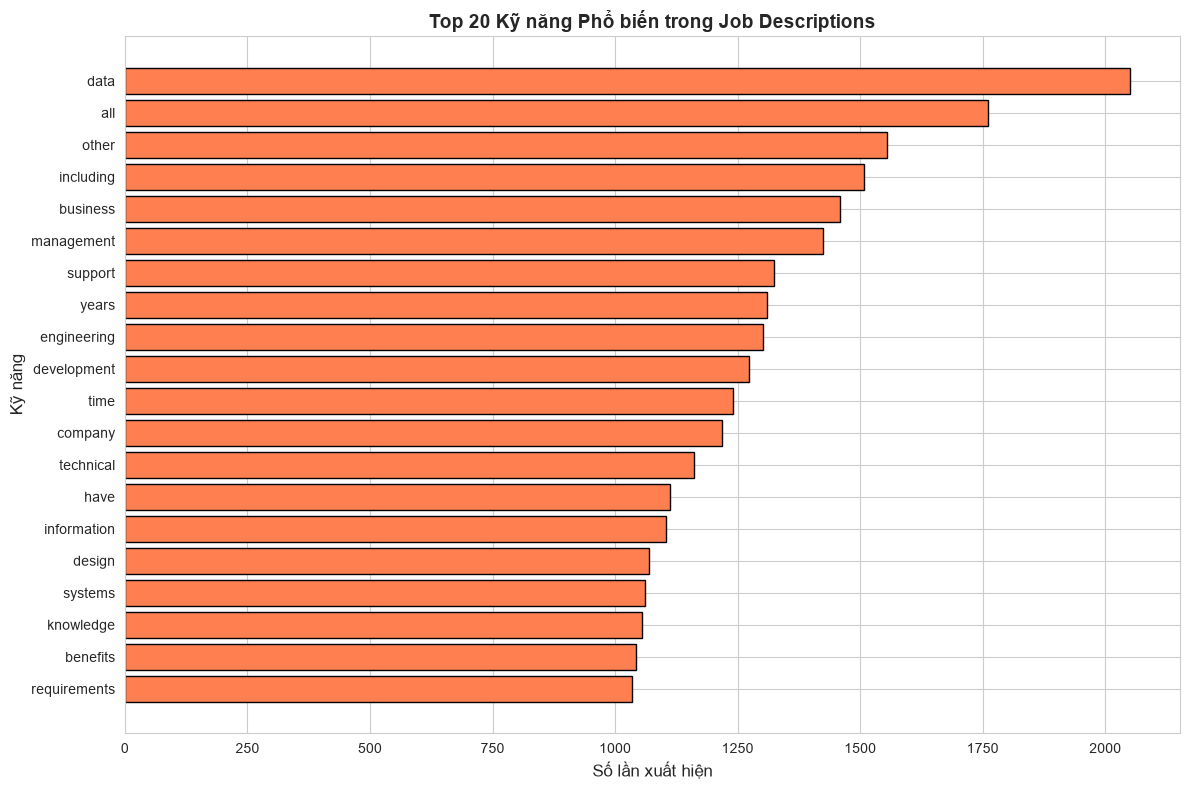


✅ Đã lưu biểu đồ tại: outputs/eda_top_skills.png

💡 Nhận xét: Các kỹ năng như 'python', 'sql', 'machine learning' xuất hiện nhiều
   => Sẽ dùng danh sách này để xây dựng tính năng 'CV Health Check'!


In [14]:
print("=" * 60)
print("BƯỚC 6: TOP KỸ NĂNG PHỔ BIẾN TRONG JD")
print("=" * 60)

# Lấy mẫu 1000 job để phân tích nhanh
sample_jobs = df_jobs_final.sample(min(1000, len(df_jobs_final)), random_state=42)

# Gộp job_description và job_skills lại
all_text = sample_jobs['clean_job_desc'] + ' ' + sample_jobs['clean_job_skills']

# Trích xuất từ khóa (độ dài >= 3 ký tự)
all_keywords = []
for text in all_text:
    words = re.findall(r'\b[a-z0-9\+\#]{3,}\b', str(text))
    all_keywords.extend(words)

# Đếm tần suất
keyword_freq = Counter(all_keywords)

# Loại bỏ stopwords (từ phổ biến không phải kỹ năng)
stopwords = {'the', 'and', 'for', 'with', 'you', 'are', 'our', 'will', 'can', 'has', 
             'this', 'that', 'from', 'your', 'job', 'work', 'team', 'role', 'position',
             'experience', 'required', 'required', 'skills', 'ability', 'strong'}
tech_keywords = {k: v for k, v in keyword_freq.items() if k not in stopwords}

# Lấy top 20 kỹ năng
top_20_skills = sorted(tech_keywords.items(), key=lambda x: x[1], reverse=True)[:20]

print(f"\n TOP 20 KỸ NĂNG PHỔ BIẾN NHẤT:")
for i, (skill, count) in enumerate(top_20_skills, 1):
    print(f"{i:2d}. {skill:20s} - {count:4d} lần xuất hiện")

# Vẽ biểu đồ
skills_df = pd.DataFrame(top_20_skills, columns=['Skill', 'Count'])
plt.figure(figsize=(12, 8))
plt.barh(skills_df['Skill'][::-1], skills_df['Count'][::-1], color='coral', edgecolor='black')
plt.xlabel('Số lần xuất hiện', fontsize=12)
plt.ylabel('Kỹ năng', fontsize=12)
plt.title('Top 20 Kỹ năng Phổ biến trong Job Descriptions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/eda_top_skills.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Đã lưu biểu đồ tại: outputs/eda_top_skills.png")
print("\n💡 Nhận xét: Các kỹ năng như 'python', 'sql', 'machine learning' xuất hiện nhiều")
print("   => Sẽ dùng danh sách này để xây dựng tính năng 'CV Health Check'!")

In [15]:
print("=" * 60)
print("BƯỚC 7: LƯU DỮ LIỆU ĐÃ XỬ LÝ")
print("=" * 60)

# Lưu Job Postings đã lọc và làm sạch
df_jobs_final.to_csv('../data/processed/jobs_tech_clean.csv', index=False, encoding='utf-8')
print(f"✅ Đã lưu Job Postings: {len(df_jobs_final):,} bản ghi")
print(f"   → File: data/processed/jobs_tech_clean.csv")

# Lưu Resume đã làm sạch
df_resumes.to_csv('../data/processed/resumes_clean.csv', index=False, encoding='utf-8')
print(f"✅ Đã lưu Resumes: {len(df_resumes):,} bản ghi")
print(f"   → File: data/processed/resumes_clean.csv")

print("\n📁 Cấu trúc file sau khi lưu:")
print("   data/processed/")
print("   ├── jobs_tech_clean.csv  (Job IT/Tech đã lọc)")
print("   └── resumes_clean.csv    (Resume đã làm sạch)")

BƯỚC 7: LƯU DỮ LIỆU ĐÃ XỬ LÝ
✅ Đã lưu Job Postings: 29,101 bản ghi
   → File: data/processed/jobs_tech_clean.csv
✅ Đã lưu Resumes: 2,483 bản ghi
   → File: data/processed/resumes_clean.csv

📁 Cấu trúc file sau khi lưu:
   data/processed/
   ├── jobs_tech_clean.csv  (Job IT/Tech đã lọc)
   └── resumes_clean.csv    (Resume đã làm sạch)
